In [1]:
import os
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             r2_score, mean_squared_error, mean_absolute_error)

%matplotlib inline
plt.rcParams["figure.dpi"] = 110

# ---- File paths (edit if your files are somewhere else) ----
HEART_CSV = r"D:\Mtech_NIT\AI-ML\Assignment-3\cleaned_merged_heart_dataset.csv"
WATER_CSV = r"D:\Mtech_NIT\AI-ML\Assignment-2\water-quality\Assignment-2\waterquality.csv"

FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

SEED = 42
keras.utils.set_random_seed(SEED)   # fixes Python, NumPy and TensorFlow seeds
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


In [2]:
def plot_history(history, metric, title, fname):
    """Training vs validation curves for loss and one metric."""
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["loss"], label="train")
    ax[0].plot(h["val_loss"], label="validation")
    ax[0].set_title(f"{title}: loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h[metric], label="train")
    ax[1].plot(h[f"val_{metric}"], label="validation")
    ax[1].set_title(f"{title}: {metric}"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, fname), bbox_inches="tight"); plt.show()

def timed_fit(model, X, y, **kw):
    t0 = time.perf_counter(); out = model.fit(X, y, **kw); return out, time.perf_counter() - t0

def timed_predict(fn, X):
    t0 = time.perf_counter(); out = fn(X); return out, time.perf_counter() - t0

In [3]:
# Classification using Artificial Neural Networkds

In [4]:
heart = pd.read_csv(HEART_CSV)
print("Raw shape:", heart.shape)
n_dup = heart.duplicated().sum()
heart = heart.drop_duplicates().reset_index(drop=True)
print(f"Dropped {n_dup} duplicate rows -> clean shape: {heart.shape}")

Xh = heart.drop(columns=["target"])
yh = heart["target"].astype(int)
print("\nClass balance:\n", yh.value_counts())
heart.head()

Raw shape: (1888, 14)
Dropped 1286 duplicate rows -> clean shape: (602, 14)

Class balance:
 target
0    310
1    292
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [5]:
Xh_train, Xh_test, yh_train, yh_test = train_test_split(
    Xh, yh, test_size=0.25, stratify=yh, random_state=SEED)

h_scaler = StandardScaler()
Xh_train_s = h_scaler.fit_transform(Xh_train)
Xh_test_s  = h_scaler.transform(Xh_test)
print("Train:", Xh_train_s.shape, " Test:", Xh_test_s.shape)

Train: (451, 13)  Test: (151, 13)


In [6]:
keras.utils.set_random_seed(SEED)
clf_ann = keras.Sequential([
    keras.Input(shape=(Xh_train_s.shape[1],)),
    layers.Dense(32, activation="relu", name="hidden_1"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu", name="hidden_2"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid", name="output"),
], name="heart_ann")

clf_ann.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                loss="binary_crossentropy", metrics=["accuracy"])
clf_ann.summary()

Model: "heart_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                     │ (None, 32)                  │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_2 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 170 epochs (best epoch: 140)
Training time: 33.16 s


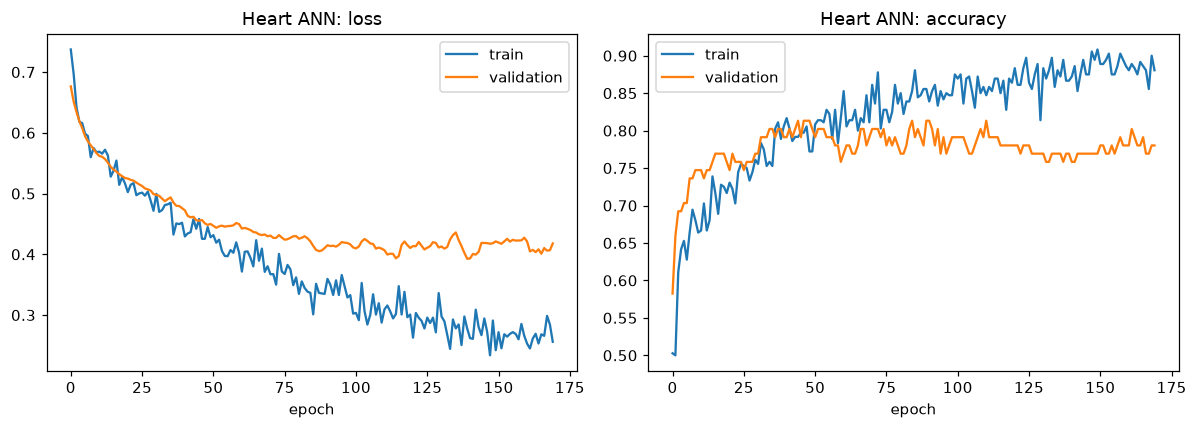

In [7]:
early_stop_c = keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)

hist_c, clf_fit_time = timed_fit(clf_ann, Xh_train_s, yh_train,
                                 validation_split=0.2, epochs=500, batch_size=16,
                                 callbacks=[early_stop_c], verbose=0)
print(f"Stopped after {len(hist_c.history['loss'])} epochs "
      f"(best epoch: {int(np.argmin(hist_c.history['val_loss'])) + 1})")
print(f"Training time: {clf_fit_time:.2f} s")

plot_history(hist_c, "accuracy", "Heart ANN", "A_training_curves.png")

In [8]:
(yh_prob, clf_pred_time) = timed_predict(lambda X: clf_ann.predict(X, verbose=0).ravel(), Xh_test_s)
yh_pred = (yh_prob >= 0.5).astype(int)

ann_clf_metrics = {
    "Accuracy":  accuracy_score(yh_test, yh_pred),
    "Precision": precision_score(yh_test, yh_pred),
    "Recall":    recall_score(yh_test, yh_pred),
    "F1":        f1_score(yh_test, yh_pred),
    "ROC-AUC":   roc_auc_score(yh_test, yh_prob),
}
for k, v in ann_clf_metrics.items():
    print(f"{k:10s}: {v:.3f}")
print(f"Predict time: {clf_pred_time*1000:.1f} ms")

Accuracy  : 0.781
Precision : 0.794
Recall    : 0.740
F1        : 0.766
ROC-AUC   : 0.841
Predict time: 238.0 ms


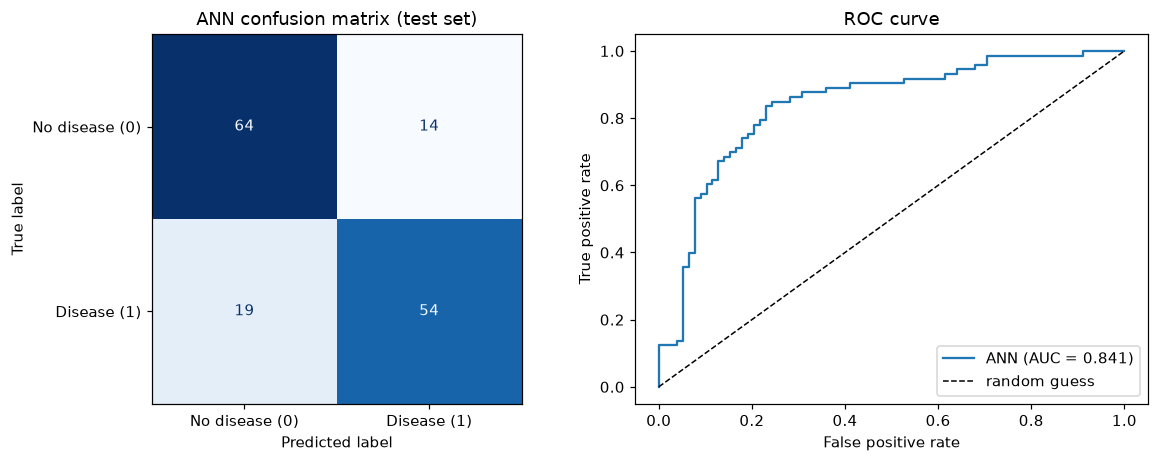

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay(confusion_matrix(yh_test, yh_pred), display_labels=["No disease (0)", "Disease (1)"]).plot(
    ax=ax[0], cmap="Blues", colorbar=False)
ax[0].set_title("ANN confusion matrix (test set)")

fpr, tpr, _ = roc_curve(yh_test, yh_prob)
ax[1].plot(fpr, tpr, label=f"ANN (AUC = {ann_clf_metrics['ROC-AUC']:.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="random guess")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
ax[1].set_title("ROC curve"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "A_confusion_roc.png"), bbox_inches="tight"); plt.show()

In [10]:
baselines_c = {
    "SVM (linear)":   (SVC(kernel="linear", random_state=SEED), True),
    "SVM (poly)":     (SVC(kernel="poly",   random_state=SEED), True),
    "SVM (RBF)":      (SVC(kernel="rbf",    random_state=SEED), True),
    "DT (depth = 5)": (DecisionTreeClassifier(max_depth=5, random_state=SEED), False),
}
rows = []
for name, (m, scaled) in baselines_c.items():
    Xtr, Xte = (Xh_train_s, Xh_test_s) if scaled else (Xh_train, Xh_test)
    _, ft = timed_fit(m, Xtr, yh_train)
    p, pt = timed_predict(m.predict, Xte)
    rows.append([name, accuracy_score(yh_test, p), precision_score(yh_test, p),
                 recall_score(yh_test, p), f1_score(yh_test, p), ft, pt])
rows.append(["ANN (32-16)", ann_clf_metrics["Accuracy"], ann_clf_metrics["Precision"],
             ann_clf_metrics["Recall"], ann_clf_metrics["F1"], clf_fit_time, clf_pred_time])

cmp_c = pd.DataFrame(rows, columns=["Model", "Accuracy", "Precision", "Recall", "F1",
                                    "Train time (s)", "Predict time (s)"]).set_index("Model")
cmp_c.to_csv("A_classification_comparison.csv")
cmp_c.round(4)

,Accuracy,Precision,Recall,F1,Train time (s),Predict time (s)
Model,,,,,,
SVM (linear),0.6954,0.6753,0.7123,0.6933,0.0374,0.0027
SVM (poly),0.7152,0.7885,0.5616,0.6560,0.0120,0.0027
SVM (RBF),0.7351,0.7324,0.7123,0.7222,0.0140,0.0067
DT (depth = 5),0.7815,0.8030,0.7260,0.7626,0.0051,0.0018
ANN (32-16),0.7815,0.7941,0.7397,0.7660,33.1629,0.2380


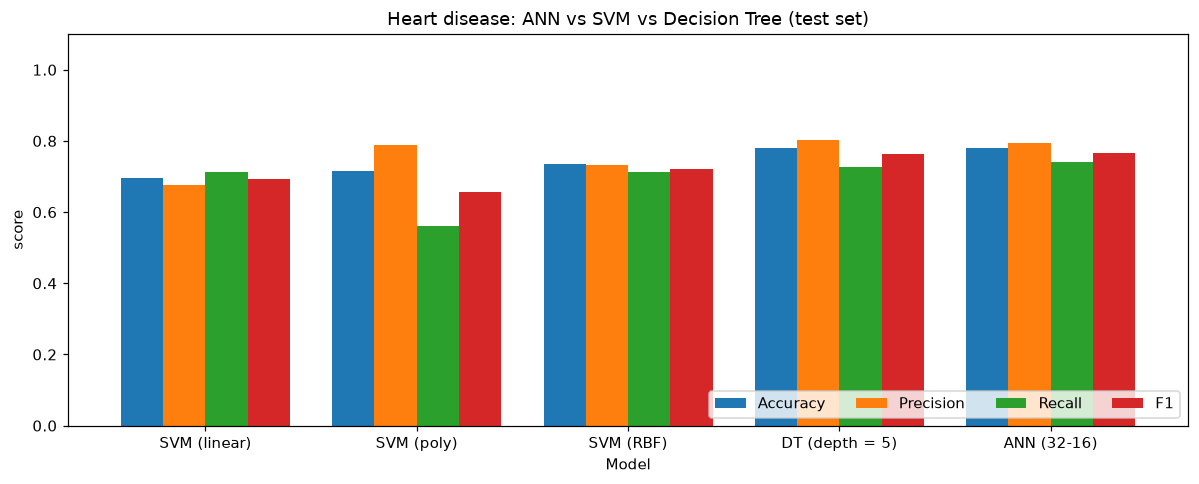

In [11]:
ax = cmp_c[["Accuracy", "Precision", "Recall", "F1"]].plot(kind="bar", figsize=(11, 4.5), width=0.8)
ax.set_ylim(0, 1.1); ax.set_ylabel("score"); ax.set_title("Heart disease: ANN vs SVM vs Decision Tree (test set)")
ax.legend(loc="lower right", ncol=4); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "A_model_comparison.png"), bbox_inches="tight"); plt.show()

In [12]:
## Regression using ANN

In [13]:
FEATURES = ["Salinity (ppt)", "pH", "SecchiDepth (m)", "WaterDepth (m)", "WaterTemp (C)", "AirTemp (C)"]
TARGET = "DissolvedOxygen (mg/L)"

water = pd.read_csv(WATER_CSV, low_memory=False)
n_before = len(water)
water = water.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f"Rows before: {n_before}  ->  after dropping missing values: {len(water)}")

Xw = water[FEATURES]
yw = water[TARGET]
water[FEATURES + [TARGET]].describe().round(2)

Rows before: 2371  ->  after dropping missing values: 1320


,Salinity (ppt),pH,SecchiDepth (m),WaterDepth (m),WaterTemp (C),AirTemp (C),DissolvedOxygen (mg/L)
count,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00,1320.00
mean,0.92,7.21,0.50,0.75,18.03,15.61,6.73
std,1.37,0.81,0.48,0.58,8.30,10.38,2.52
min,0.00,0.30,0.00,0.01,0.00,-17.78,0.00
25%,0.00,6.50,0.30,0.44,11.00,8.89,4.80
50%,0.00,7.00,0.40,0.68,18.90,16.67,6.60
75%,1.50,7.50,0.60,0.90,25.00,23.89,8.61
max,9.00,9.90,7.40,7.50,74.00,33.50,15.10


In [14]:
Xw_train, Xw_test, yw_train, yw_test = train_test_split(Xw, yw, test_size=0.2, random_state=40)

w_scaler = StandardScaler()
Xw_train_s = w_scaler.fit_transform(Xw_train)
Xw_test_s  = w_scaler.transform(Xw_test)
print("Train:", Xw_train_s.shape, " Test:", Xw_test_s.shape)

Train: (1056, 6)  Test: (264, 6)


In [15]:
keras.utils.set_random_seed(SEED)
reg_ann = keras.Sequential([
    keras.Input(shape=(Xw_train_s.shape[1],)),
    layers.Dense(64, activation="relu", name="hidden_1"),
    layers.Dense(32, activation="relu", name="hidden_2"),
    layers.Dense(16, activation="relu", name="hidden_3"),
    layers.Dense(1, name="output"),
], name="water_ann")

reg_ann.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3), loss="mse", metrics=["mae"])
reg_ann.summary()

Model: "water_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ hidden_1 (Dense)                     │ (None, 64)                  │             448 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_2 (Dense)                     │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ hidden_3 (Dense)                     │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ output (Dense)                       │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,073 (12.00 KB)

 Trainable params: 3,073 (12.00 KB)

 Non-trainable params: 0 (0.00 B)

Stopped after 91 epochs (best epoch: 61)
Training time: 19.67 s


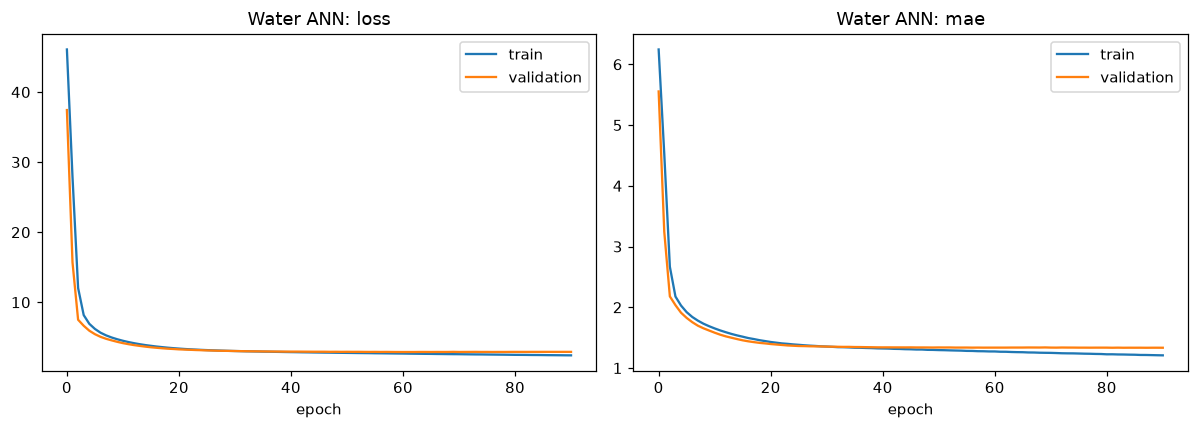

In [16]:
early_stop_r = keras.callbacks.EarlyStopping(monitor="val_loss", patience=30, restore_best_weights=True)

hist_r, reg_fit_time = timed_fit(reg_ann, Xw_train_s, yw_train.values,
                                 validation_split=0.2, epochs=500, batch_size=32,
                                 callbacks=[early_stop_r], verbose=0)
print(f"Stopped after {len(hist_r.history['loss'])} epochs "
      f"(best epoch: {int(np.argmin(hist_r.history['val_loss'])) + 1})")
print(f"Training time: {reg_fit_time:.2f} s")

plot_history(hist_r, "mae", "Water ANN", "B_training_curves.png")

In [17]:
(yw_pred, reg_pred_time) = timed_predict(lambda X: reg_ann.predict(X, verbose=0).ravel(), Xw_test_s)

ann_reg_metrics = {
    "R2":   r2_score(yw_test, yw_pred),
    "RMSE": np.sqrt(mean_squared_error(yw_test, yw_pred)),
    "MAE":  mean_absolute_error(yw_test, yw_pred),
}
for k, v in ann_reg_metrics.items():
    print(f"{k:5s}: {v:.3f}")
print(f"Predict time: {reg_pred_time*1000:.1f} ms")

R2   : 0.456
RMSE : 1.848
MAE  : 1.390
Predict time: 253.8 ms


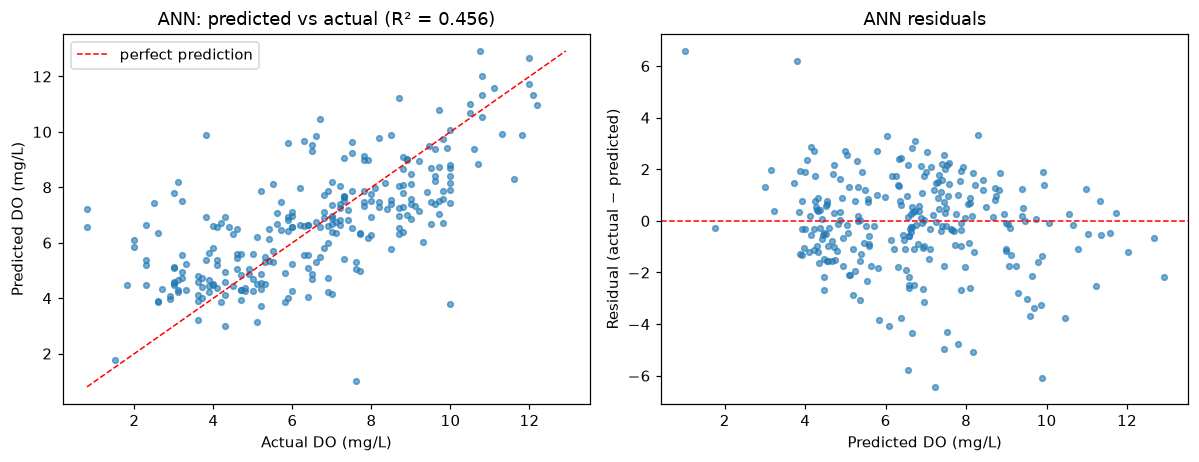

In [18]:
resid = yw_test.values - yw_pred
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
lo, hi = min(yw_test.min(), yw_pred.min()), max(yw_test.max(), yw_pred.max())
ax[0].scatter(yw_test, yw_pred, s=14, alpha=0.6)
ax[0].plot([lo, hi], [lo, hi], "r--", lw=1, label="perfect prediction")
ax[0].set_xlabel("Actual DO (mg/L)"); ax[0].set_ylabel("Predicted DO (mg/L)")
ax[0].set_title(f"ANN: predicted vs actual (R² = {ann_reg_metrics['R2']:.3f})"); ax[0].legend()

ax[1].scatter(yw_pred, resid, s=14, alpha=0.6)
ax[1].axhline(0, color="r", ls="--", lw=1)
ax[1].set_xlabel("Predicted DO (mg/L)"); ax[1].set_ylabel("Residual (actual − predicted)")
ax[1].set_title("ANN residuals")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "B_pred_vs_actual_residuals.png"), bbox_inches="tight"); plt.show()

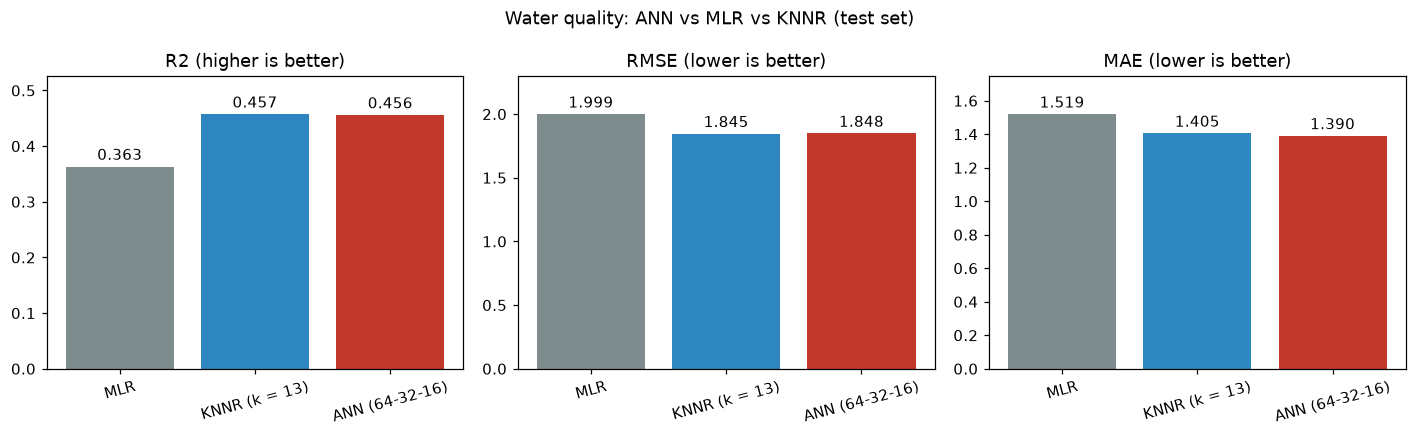

In [19]:
baselines_r = {
    "MLR":          LinearRegression(),
    "KNNR (k = 13)": KNeighborsRegressor(n_neighbors=13),
}
rows = []
for name, m in baselines_r.items():
    _, ft = timed_fit(m, Xw_train_s, yw_train)
    p, pt = timed_predict(m.predict, Xw_test_s)
    rows.append([name, r2_score(yw_test, p), np.sqrt(mean_squared_error(yw_test, p)),
                 mean_absolute_error(yw_test, p), ft, pt])
rows.append(["ANN (64-32-16)", ann_reg_metrics["R2"], ann_reg_metrics["RMSE"],
             ann_reg_metrics["MAE"], reg_fit_time, reg_pred_time])

cmp_r = pd.DataFrame(rows, columns=["Model", "R2", "RMSE", "MAE",
                                    "Train time (s)", "Predict time (s)"]).set_index("Model")
cmp_r.to_csv("B_regression_comparison.csv")
cmp_r.round(4)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
colors = ["#7f8c8d", "#2e86c1", "#c0392b"]
for a, col in zip(ax, ["R2", "RMSE", "MAE"]):
    bars = a.bar(cmp_r.index, cmp_r[col], color=colors)
    a.bar_label(bars, fmt="%.3f", padding=2)
    a.set_ylim(0, max(cmp_r[col].max(), 0) * 1.15)
    a.set_title(col + (" (higher is better)" if col == "R2" else " (lower is better)"))
    a.tick_params(axis="x", rotation=15)
fig.suptitle("Water quality: ANN vs MLR vs KNNR (test set)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "B_model_comparison.png"), bbox_inches="tight"); plt.show()

In [20]:
print("PART A — Classification (Heart Disease)")
print(cmp_c[["Accuracy", "Precision", "Recall", "F1"]].round(3).to_string())
print("\nPART B — Regression (Water Quality)")
print(cmp_r[["R2", "RMSE", "MAE"]].round(3).to_string())
print(f"\nFigures saved in: {os.path.abspath(FIG_DIR)}")

PART A — Classification (Heart Disease)
                Accuracy  Precision  Recall     F1
Model                                             
SVM (linear)       0.695      0.675   0.712  0.693
SVM (poly)         0.715      0.788   0.562  0.656
SVM (RBF)          0.735      0.732   0.712  0.722
DT (depth = 5)     0.781      0.803   0.726  0.763
ANN (32-16)        0.781      0.794   0.740  0.766

PART B — Regression (Water Quality)
                   R2   RMSE    MAE
Model                              
MLR             0.363  1.999  1.519
KNNR (k = 13)   0.457  1.845  1.405
ANN (64-32-16)  0.456  1.848  1.390

Figures saved in: D:\Mtech_NIT\AI-ML\Assignment-4\figures
